<b> Import Library, find available devices </b>

In [ ]:
# Uses 2 SMUs and 1 MM.

import pyvisa                    # Importing the pyvisa library for instrument communication
import time                      # Importing the time module to handle time-related tasks (e.g., delays)
import matplotlib.pyplot as plt  # Importing matplotlib.pyplot for plotting graphs and visualizing data
import numpy as np               # Importing numpy for numerical operations, particularly with arrays
import pandas as dp              # Importing pandas as dp for data manipulation and analysis
import os                        # Importing os to interact with the operating system, such as handling file paths
import csv                       # Importing csv to read from and write to CSV files
from datetime import date           # Importing date to read current date
rm = pyvisa.ResourceManager()    # Create a ResourceManager object, which manages communication with instruments
rm.list_resources()              # List all available resources (e.g., connected instruments) managed by pyvisa

C:\Users\spnew\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\gpib_ctypes\gpib\gpib.py:54: UserWarning: GPIB library not found. Please manually load it using _load_lib(filename). All GPIB functions will raise OSError until the library is manually loaded.
  warnings.warn(message)
C:\Users\spnew\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyvisa_py\tcpip.py:122: UserWarning: TCPIP::hislip resource discovery requires the zeroconf package to be installed... try 'pip install zeroconf'
  warnings.warn(


()

In [ ]:

def establish_connection(address, query):
    instrument = rm.open_resource(address)   # Open a connection to the instrument with the address and assign it to SM_VIN
    instrument.read_termination = '\n'       # Set the read termination character to a newline. This tells pyvisa when to consider a message as complete when reading from the instrument.
    instrument.write_termination = '\n'      # Set the write termination character to a newline. This ensures that each command sent to the instrument is properly terminated.
    instrument.baud_rate = 9600              # Set the baud rate for serial communication to 9600. This is the speed at which data is transmitted over the serial connection.
    print(instrument)                        # Print the resource object to display its properties
    if query != "NONE":
        print(instrument.query(query))       # Send the query to the instrument and print its response. The "*IDN?" command usually asks the instrument to identify itself (e.g., manufacturer, model number).
    return instrument

SM1 = establish_connection('GPIB6::20::INSTR', '*IDN?')
SM_VDD1 = establish_connection('', '*IDN?')
MM1 = establish_connection('USB0::0x2A8D::0x0101::MY54505624::INSTR', '*IDN?')  
CHAMBER = establish_connection('GPIB6::6::INSTR', 'STATUS?')          

NameError: name 'estabilish_connection' is not defined

In [12]:
VDD = 1.2
x = np.arange(0, 1.21, 0.01)
TEMPlist = [125, 100, 75, 50, 27, 0, -27, -50, -75, -100, -125, -150, -175]      # List of temperatures for test

<b> Test Sweep Definitions </b>

In [ ]:
def chamber_init():
    CHAMBER.write("ON")
    CHAMBER.write("RATE=20")     # Sets the speed at which the chamber will ramp to change TEMP
    CHAMBER.write("WAIT=30")     # Sets the time that the chamber will wait once the desired temperature is reached before measurements start
    CHAMBER.write("HON")         # Turns heat on
    CHAMBER.write("CON")         # Turns cool on
    CHAMBER.write("PIDA=3")
    time.sleep(1) 

    print(CHAMBER.query("RATE?"))
    print(CHAMBER.query("WAIT?"))

def SMU_init(SMU):
    # These are set-up commands that previous code has used. I'm leaving them commented 
    # out for now in case there's a reason they weren't included in the last version of this code.
    # SMU.write("*RST")                     # Resets
    # SMU.write("*CLS")                     # Clears
    # SMU.write("TRAC:CLE")                 # Clears trace buffers
    # SMU.write("TRIG:CLE")                 # Clears triggers
    # SMU.write("SYST:BEEP:STAT OFF")       # Turn off the beeper on the SMU
    # SMU.timeout = 150000                  # Set timeout for SMU operations
    # SMU.write("SYST:AZER ON")             # Enable auto-zero
    # SMU.write("SOUR:FUNC VOLT")           # Set source function to voltage
    # SMU.write("SENS:FUNC 'CURR'")         # Set measurement function to current
      
    SMU.write(":CONF:CURR")                 # Configure the SMU to measure current
    SMU.write("OUTP:STAT 0")                # Turn off the source meter
    SMU.write("SOUR:VOLT:RANG 3.3")  
    SMU.write("SENS:CURR:PROT:LEV 0.0105")  # Set the current protection level (compliance) to 10.5 mA. This limits the maximum current to protect the device under test.
    SMU.write("SENS:CURR:RANG 1E-2")        # Set the current measurement range to 10 mA. This sets the expected maximum current for accurate measurement.
    SMU.write("CURR:NPLC .01")

def MM_init(MM):
    MM.write("ABOR")
    MM.write("*RST; *CLS")
    MM.write(":CONF:VOLT:DC")
    MM.write("VOLT:NPLC .1")
    MM.write("VOLT:DC:RANG 2")
    MM.write("VOLT:DC:ZERO:AUTO OFF")

# Does not initialize chamber
def initialize_all():
    SMU_init(SM1)
    SMU_init(SM_VDD1)
    MM_init(MM1)

def SMU_on(SMU, val):
    SMU.write(":SOUR:VOLT:MODE FIX")
    SMU.write(f"SOUR:VOLT:LEV {val}")
    SMU.write("OUTP ON")

def SMUs_on():
    SMU_on(SM_VDD1, VDD)
    SMU_on(SM1, 0)

# To manually check the values, if you ever need to look real quick
def measure_all():
    SM1.query(":READ?")
    SM_VDD1.query(":READ?")
    
def initialize_plot(device_num):
    fig, ax = plt.subplots(layout='constrained')
    ax.set_title(f'Device {device_num} Sweep', fontdict={'fontsize': 16, 'fontweight': 'bold'}, y = 1.03)
    ax.set_xlabel('Input Voltage (V)', fontdict={'fontsize': 12})
    ax.set_ylabel('Supply Current (A)', fontdict={'fontsize': 12})
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.set_xticks(np.arange(0, 1.3, 0.1))
    ax.set_xlim(0, 1.2)
    #ax.set_yticks(np.arange(0, 1.3, 0.1))
    #ax.set_ylim(0, 1.2)
    ax.grid()
    return fig, ax

def test_sweep(TEMP, local):
    y1=[]
    for i in range(121):        # Loop from 0 to 120. Will be divided by 100 to get 0mV to 1.2V.                                                          
        val = i / 100                                        # Convert the current loop index into a floating-point voltage value
        ############ Sets VIN voltage ############                
        SM1.write("SOUR:VOLT:LEV " + str(val))          # Write the command to set the VIN voltage on the source meter        
        time.sleep(.005)
        ######## Measure ILOAD and others ########
        
        #MM1.write("*TRG")
        #time.sleep(.05)
        y1.append(SM_VDD1.query(":READ?").split(',')[1])
    SM1.write("SOUR:VOLT:LEV 0")          # Write the command to set the VIN voltage on the source meter        

    df = dp.DataFrame({'V Input':x, 'Supply Current Output':np.asarray(y1, dtype='float')})   # Create a DataFrame
    csv_path=os.path.join(local, 'Device_1.csv')        # Define the file path for saving the CSV file in the specified directory.
    df.to_csv(csv_path, index=False)

    # Generate and format a I/V plots for a given temperature
    fig, M1plot = initialize_plot("1")
    M1plot.plot(x, np.asarray(y1, dtype='float'))
    M1plot.plot(np.asarray(y1, dtype='float'), x) #INCLUDE FOR BUTTERFLY PLOT
    plt.close(fig)
    fig.savefig(os.path.join(local, "Device_1_Sweep_T_" + str(TEMP) + ".png"))

    return y1



<b> Test Run of Sweep (Single Temperature)</b>

In [ ]:
DATE="Omar_Testing_Results/"+str(date.today())     # Create a directory with the date. If the directory already exists, it won't raise an error due to exist_ok=True
os.makedirs(DATE, exist_ok=True)
i=1
local=str(DATE)+"/Test_Run_"+str(i)                        # The temperature of the experiment gets set as the sub directory name. DUT_"directory_name"/yyyy-mm-dd/TEMP_"TEMP"
while os.path.isdir(local) == True and len(os.listdir(local)) != 0 :               # Keeps track of the number of tests done today and checks if the folder is empty
    local=str(DATE)+"/Test_Run_"+str(i)                
    i=i+1
os.makedirs(local, exist_ok=True)
initialize_all()
time.sleep(1)
SMUs_on()
time.sleep(1)
test_sweep(27, local)

(['+1.14841794E+00',
  '+1.14681000E+00',
  '+1.14791889E+00',
  '+1.14624175E+00',
  '+1.14629030E+00',
  '+1.14584014E+00',
  '+1.14595062E+00',
  '+1.14615793E+00',
  '+1.14611696E+00',
  '+1.14581793E+00',
  '+1.14559157E+00',
  '+1.14519791E+00',
  '+1.14474808E+00',
  '+1.14431030E+00',
  '+1.14342458E+00',
  '+1.14277029E+00',
  '+1.14209726E+00',
  '+1.14138170E+00',
  '+1.14085473E+00',
  '+1.14044455E+00',
  '+1.13997377E+00',
  '+1.13982106E+00',
  '+1.13952328E+00',
  '+1.13944043E+00',
  '+1.13932487E+00',
  '+1.13876582E+00',
  '+1.13838328E+00',
  '+1.13753058E+00',
  '+1.13660485E+00',
  '+1.13569596E+00',
  '+1.13451120E+00',
  '+1.13314071E+00',
  '+1.13196167E+00',
  '+1.13070705E+00',
  '+1.12977117E+00',
  '+1.12882323E+00',
  '+1.12785181E+00',
  '+1.12690481E+00',
  '+1.12619305E+00',
  '+1.12533020E+00',
  '+1.12429526E+00',
  '+1.12281589E+00',
  '+1.12112827E+00',
  '+1.11893746E+00',
  '+1.11675808E+00',
  '+1.11345013E+00',
  '+1.11034440E+00',
  '+1.1069570

<b> Test Protocol (All Temperatures) </b>

NameError: name 'CHAMBER' is not defined

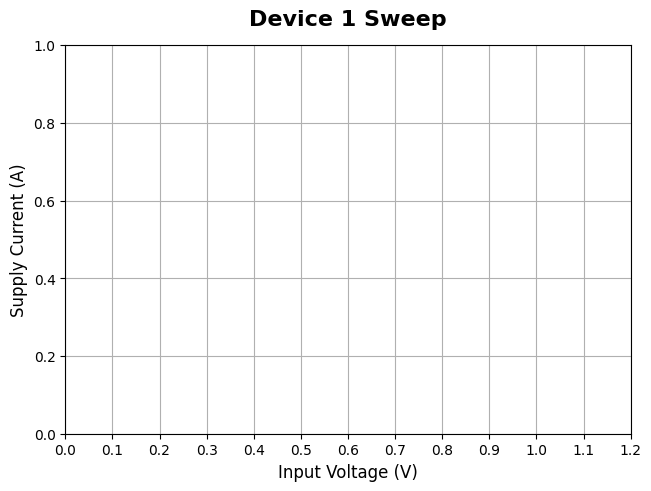

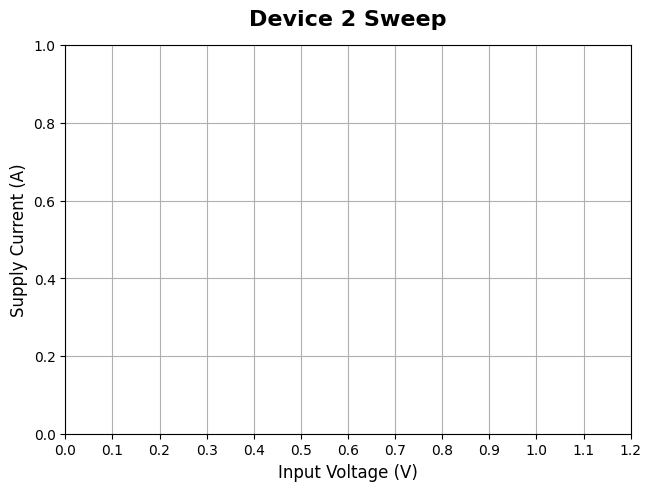

In [ ]:
# Create directory
DATE="Omar_Testing_Results/"+str(date.today())     # Create a directory with the date. If the directory already exists, it won't raise an error due to exist_ok=True
os.makedirs(DATE, exist_ok=True)
i=1
DUT=str(DATE)+"/DUT_"+str(i)
while os.path.isdir(DUT) == True and len(os.listdir(DUT)) != 0 :               # Keeps track of the number of tests done today and checks if the folder is empty
    DUT=str(DATE)+"/DUT_"+str(i)                
    i=i+1
os.makedirs(DUT, exist_ok=True)                 # Create another directory for test date for this test


################## Initial creation and format of overall IV curves ##################
# Create a color map for the plots
cm=plt.get_cmap('gist_rainbow')

# Create figures for the overall Vout plots
M1fig, M1plot = initialize_plot("1")
M1plot.set_prop_cycle ('color', [cm(1.*i/len(TEMPlist)) for i in range(len(TEMPlist))])

chamber_init()
time.sleep(1)
initialize_all()
time.sleep(1)
SMUs_on()
time.sleep(1)

for TEMP in TEMPlist:
    local=str(DUT)+"/TEMP_"+str(TEMP)                          # The temperature of the experiment gets set as the sub directory name. DUT_"directory_name"/yyyy-mm-dd/TEMP_"TEMP"
    os.makedirs(local, exist_ok=True)                           # Create a directory with the given name. If the directory already exists, it won't raise an error due to exist_ok=True
    
    CHAMBER.write("WAIT=30")                                    # Resets the wait time of the temp chamber to 30 minutes so it doesn't time out mid test
    CHAMBER.write("SET=" + str(TEMP))
    # TODO: There is probably a better way to check for temperature settling and do wait time
    while (CHAMBER.query("STATUS?")[3] == 'N'):                 # Checks if the temperature chamber has arrived at TEMP yet or not
        time.sleep(15)
        print(CHAMBER.query("STATUS?"))  
    print(CHAMBER.query("STATUS?"))
    time.sleep(300)                                             # Soak time
    y1 = test_sweep(TEMP, local)

    M1plot.plot(x, np.asarray(y1, dtype='float'), label=f"T={TEMP} °C")

for line in M1plot.legend(bbox_to_anchor=(1.02, 1), loc='upper left').get_lines():
    line.set_linewidth(2.5)
M1fig.savefig(os.path.join(DUT, "Device_1_Sweep.png"))

CHAMBER.write("SET=30")                             # Sets the temperature back to room temp once test is complete                      
while (CHAMBER.query("STATUS?")[3] == 'N'):         # Checks if chamber has arrived at room temp
    time.sleep(15)
CHAMBER.write("STOP")                               # Once chamber is at room temp, chamber stops operation